<a href="https://colab.research.google.com/github/Alex-So-Ma/Data_Analysis/blob/main/Copia_de_Proyecto_Introducci%C3%B3n_al_An%C3%A1lisis_Estad%C3%ADstico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROYECTO: INTRODUCCIÓN AL ANÁLISIS ESTADÍSTICO**

Una vez visto el ***Módulo 2: Fundamentos Estadísticos***, se presenta la siguiente actividad para que el alumnado pueda poner a prueba lo aprendido durante este módulo.

Dentro de la siguiente dinámica, realizar el siguiente **análisis exploratorio con aprendizaje estadístico** de cualquier dataset proveniente de la librería de ***Seaborn*** que no haya sido utilizado.

Se sugiere los siguientes puntos para llevar a cabo lo anterior:

*   Realizar un **análisis descriptivo** para comprender comportamiento de la descripción de los datos a través de resúmenes.
*   Realizar un **aprendizaje estadístico** para predecir comportamientos lineales de datos a través de la regresión lineal simple.

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

#Elección del dataset

In [ ]:
#Vemos lo datasets disponibles en seaborn
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [ ]:
#Esocgí el dataset planets para mi proyecto
df_proyect = sns.load_dataset('planets')
df_proyect

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300000,7.10,77.40,2006
1,Radial Velocity,1,874.774000,2.21,56.95,2008
2,Radial Velocity,1,763.000000,2.60,19.84,2011
3,Radial Velocity,1,326.030000,19.40,110.62,2007
4,Radial Velocity,1,516.220000,10.50,119.47,2009
...,...,...,...,...,...,...
1030,Transit,1,3.941507,NaN,172.00,2006
1031,Transit,1,2.615864,NaN,148.00,2007
1032,Transit,1,3.191524,NaN,174.00,2007
1033,Transit,1,4.125083,NaN,293.00,2008


In [ ]:
df_proyect.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1035 entries, 0 to 1034
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   method          1035 non-null   object 
 1   number          1035 non-null   int64  
 2   orbital_period  992 non-null    float64
 3   mass            513 non-null    float64
 4   distance        808 non-null    float64
 5   year            1035 non-null   int64  
dtypes: float64(3), int64(2), object(1)
memory usage: 48.6+ KB


In [ ]:
df_proyect.describe()

,number,orbital_period,mass,distance,year
count,1035.000000,992.000000,513.000000,808.000000,1035.000000
mean,1.785507,2002.917596,2.638161,264.069282,2009.070531
std,1.240976,26014.728304,3.818617,733.116493,3.972567
min,1.000000,0.090706,0.003600,1.350000,1989.000000
25%,1.000000,5.442540,0.229000,32.560000,2007.000000
50%,1.000000,39.979500,1.260000,55.250000,2010.000000
75%,2.000000,526.005000,3.040000,178.500000,2012.000000
max,7.000000,730000.000000,25.000000,8500.000000,2014.000000


#Análisis univariable

##number

Nos dice el número de planetas en el sistema.

In [ ]:
#Para simplificar el proceso del análisis univariable de cada columna cree
#bloques de código donde solo se tiene que escribir el nombre de la columna
#a analizar (describir) en la variable column_td (column_t<o>d<escribe>)

column_td='number' #asignamos el nombre de la columna a analizar

df_proyect_copy=df_proyect.dropna(subset=[column_td]) #creamos un dataframe sin las filas que tienen valores null en la columna a analizar

mtc = mtc_number = [round(df_proyect_copy[column_td].mean(), 2),            #creamos una lista con la media mediana y moda de la columna, para simplificar el uso de este bloque
                      round(df_proyect_copy[column_td].median(), 2),        #de código tenemos dos variables iguales, mtc que se usa para el resto del bloque
                      round(df_proyect_copy[column_td].mode().iloc[0], 2)]  #y mtc_number que guarda la información de la columna number en caso de que la necesitemos después

std = std_number = np.std(df_proyect_copy[column_td]) #lo mismo, std se usa para el resto de estos bloques de código reutilizables y std_number para guardar la información de la columna

percentil = percentil_number = np.percentile(df_proyect_copy[column_td], [25, 50, 75]) #lo mismo, percentil se usa para el resto de estos bloques de código reutilizables
                                                                                       #y percentil_number para guardar la información de la columna
q_1 = round(percentil[0], 2)
q_3 = round(percentil[2], 2)
iqr = q_3 - q_1

print(f'Las MTC son: media {mtc[0]}, mediana {mtc[1]} y moda {mtc[2]}')
print(f'Las medidas de dispersión son: desviación estándar {std} y cuartiles {percentil}')

Las MTC son: media 1.79, mediana 1.0 y moda 1
Las medidas de dispersión son: desviación estándar 1.2403765240623805 y cuartiles [1. 1. 2.]


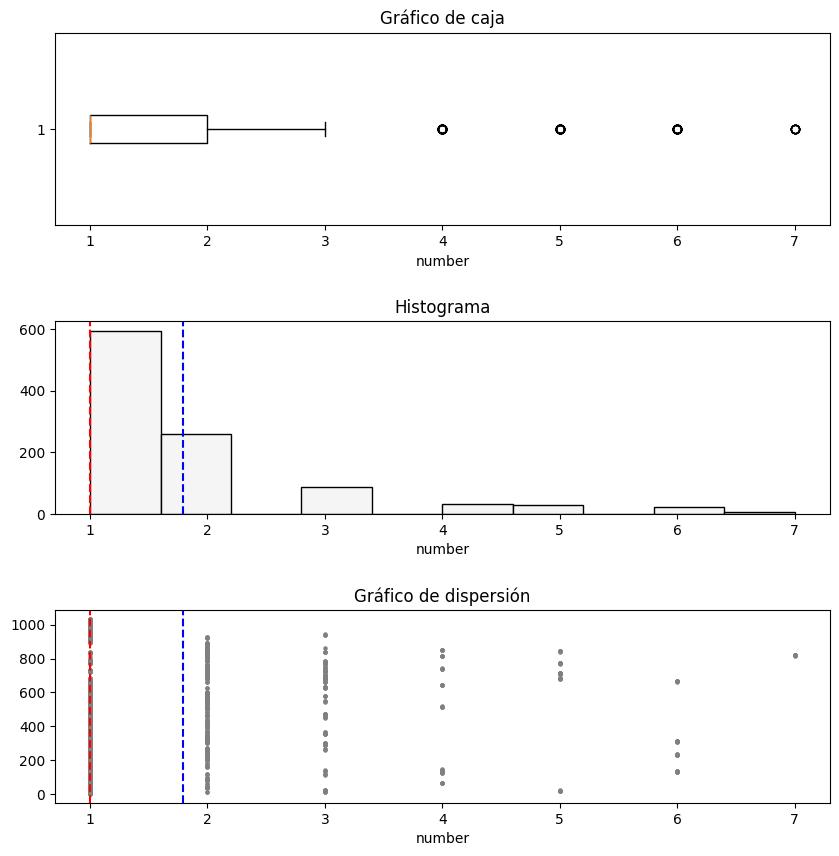

In [ ]:
fig, ax = plt.subplots(3, figsize = (10, 10), gridspec_kw = {'hspace': 0.5}) #definimos el array de subplots
x_label = column_td #la etiqueta del eje de las x será el nombre de la columna
# usamos la información que se guardo en la lista reutilizable mtc que en este caso tiene la información de la columna number
media = mtc[0]
mediana = mtc[1]

ax[0].boxplot(df_proyect_copy[x_label], vert = False) #gráfico de caja
ax[0].set_title('Gráfico de caja')
ax[0].set_xlabel(x_label)

ax[1].hist(df_proyect_copy[x_label], edgecolor = 'black', color = 'whitesmoke') #histograma
ax[1].axvline(x = mediana, linestyle = '--', color = 'red')
ax[1].axvline(x = media, linestyle = '--', color = 'blue')
ax[1].set_title('Histograma')
ax[1].set_xlabel(x_label)

x = range(len(df_proyect_copy[x_label]))
y = df_proyect_copy[x_label]

ax[2].scatter(y, x, s = 5, color = 'gray') #dipersión de los datos
ax[2].axvline(x = mediana, linestyle = '--', color = 'red')
ax[2].axvline(x = media, linestyle = '--', color = 'blue')
ax[2].set_title('Gráfico de dispersión')
ax[2].set_xlabel(x_label)

plt.show()

##orbital period

El tiempo que tarda el planeta en orbitar su estrella.

In [ ]:
column_td='orbital_period' #reutilizamos los bloques de código solo cambiamos de columna aquí

df_proyect_copy=df_proyect.dropna(subset=[column_td])

mtc = mtc_orbital_period = [round(df_proyect_copy[column_td].mean(), 2),
                      round(df_proyect_copy[column_td].median(), 2),
                      round(df_proyect_copy[column_td].mode().iloc[0], 2)] #reutilizamos los bloques de código solo cambiamos de columna aquí

std = std_orbital_period = np.std(df_proyect_copy[column_td]) #reutilizamos los bloques de código solo cambiamos de columna aquí

percentil = percentil_orbital_period = np.percentile(df_proyect_copy[column_td], [25, 50, 75]) #reutilizamos los bloques de código solo cambiamos de columna aquí

q_1 = round(percentil[0], 2)
q_3 = round(percentil[2], 2)
iqr = q_3 - q_1

print(f'Las MTC son: media {mtc[0]}, mediana {mtc[1]} y moda {mtc[2]}')
print(f'Las medidas de dispersión son: desviación estándar {std} y cuartiles {percentil}')

Las MTC son: media 2002.92, mediana 39.98 y moda 123.0
Las medidas de dispersión son: desviación estándar 26001.61273564429 y cuartiles [  5.4425405  39.9795    526.005    ]


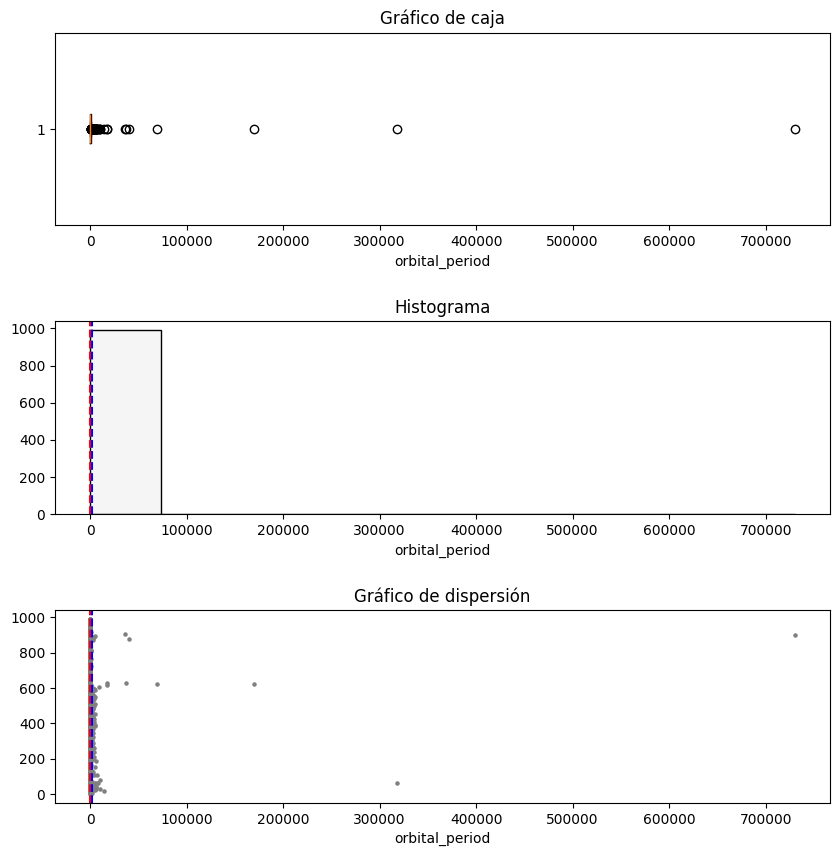

In [ ]:
fig, ax = plt.subplots(3, figsize = (10, 10), gridspec_kw = {'hspace': 0.5})
x_label = column_td
media = mtc[0]
mediana = mtc[1]

ax[0].boxplot(df_proyect_copy[x_label], vert = False)
ax[0].set_title('Gráfico de caja')
ax[0].set_xlabel(x_label)

ax[1].hist(df_proyect_copy[x_label], edgecolor = 'black', color = 'whitesmoke')
ax[1].axvline(x = mediana, linestyle = '--', color = 'red')
ax[1].axvline(x = media, linestyle = '--', color = 'blue')
ax[1].set_title('Histograma')
ax[1].set_xlabel(x_label)

x = range(len(df_proyect_copy[x_label]))
y = df_proyect_copy[x_label]

ax[2].scatter(y, x, s = 5, color = 'gray')
ax[2].axvline(x = mediana, linestyle = '--', color = 'red')
ax[2].axvline(x = media, linestyle = '--', color = 'blue')
ax[2].set_title('Gráfico de dispersión')
ax[2].set_xlabel(x_label)

plt.show()

##mass

Masa del planeta

In [ ]:
column_td='mass' #reutilizamos los bloques de código solo cambiamos de columna aquí

df_proyect_copy=df_proyect.dropna(subset=[column_td])

mtc = mtc_mass = [round(df_proyect_copy[column_td].mean(), 2),
                      round(df_proyect_copy[column_td].median(), 2),
                      round(df_proyect_copy[column_td].mode().iloc[0], 2)] #reutilizamos los bloques de código solo cambiamos de columna aquí

std = std_mass = np.std(df_proyect_copy[column_td]) #reutilizamos los bloques de código solo cambiamos de columna aquí

percentil = percentil_mass = np.percentile(df_proyect_copy[column_td], [25, 50, 75]) #reutilizamos los bloques de código solo cambiamos de columna aquí

q_1 = round(percentil[0], 2)
q_3 = round(percentil[2], 2)
iqr = q_3 - q_1

print(f'Las MTC son: media {mtc[0]}, mediana {mtc[1]} y moda {mtc[2]}')
print(f'Las medidas de dispersión son: desviación estándar {std} y cuartiles {percentil}')

Las MTC son: media 2.64, mediana 1.26 y moda 1.8
Las medidas de dispersión son: desviación estándar 3.814892986837594 y cuartiles [0.229 1.26  3.04 ]


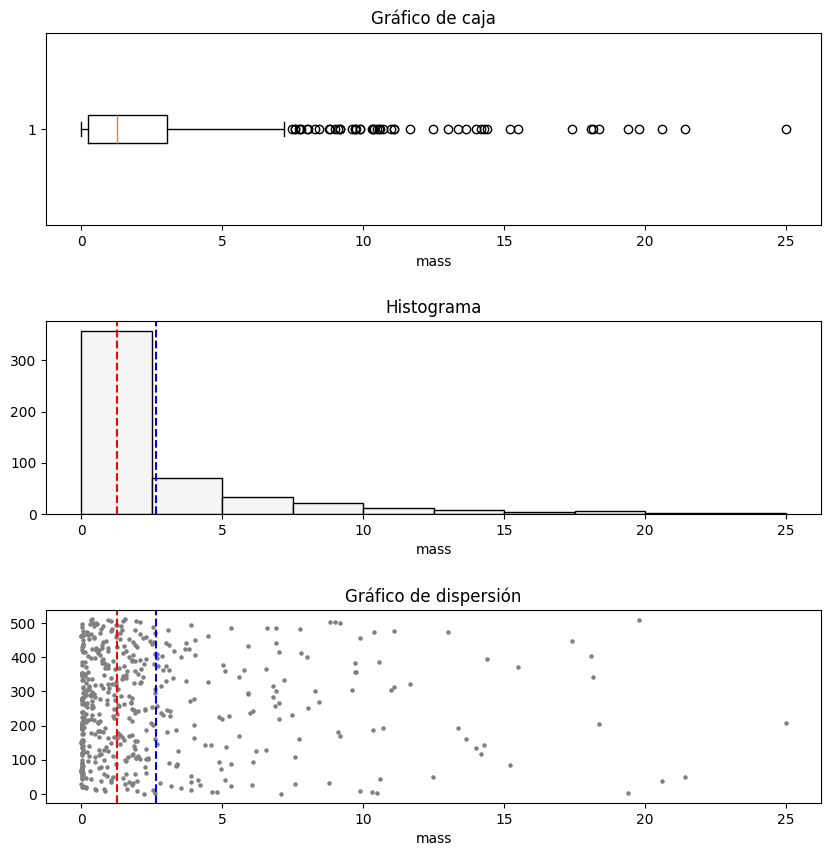

In [ ]:
fig, ax = plt.subplots(3, figsize = (10, 10), gridspec_kw = {'hspace': 0.5})
x_label = column_td
media = mtc[0]
mediana = mtc[1]

ax[0].boxplot(df_proyect_copy[x_label], vert = False)
ax[0].set_title('Gráfico de caja')
ax[0].set_xlabel(x_label)

ax[1].hist(df_proyect_copy[x_label], edgecolor = 'black', color = 'whitesmoke')
ax[1].axvline(x = mediana, linestyle = '--', color = 'red')
ax[1].axvline(x = media, linestyle = '--', color = 'blue')
ax[1].set_title('Histograma')
ax[1].set_xlabel(x_label)

x = range(len(df_proyect_copy[x_label]))
y = df_proyect_copy[x_label]

ax[2].scatter(y, x, s = 5, color = 'gray')
ax[2].axvline(x = mediana, linestyle = '--', color = 'red')
ax[2].axvline(x = media, linestyle = '--', color = 'blue')
ax[2].set_title('Gráfico de dispersión')
ax[2].set_xlabel(x_label)

plt.show()

##distance

Distancia entre el planeta y la Tierra (nosotros)

In [ ]:
column_td='distance' #reutilizamos los bloques de código solo cambiamos de columna aquí

df_proyect_copy=df_proyect.dropna(subset=[column_td])

mtc = mtc_distance = [round(df_proyect_copy[column_td].mean(), 2),
                      round(df_proyect_copy[column_td].median(), 2),
                      round(df_proyect_copy[column_td].mode().iloc[0], 2)] #reutilizamos los bloques de código solo cambiamos de columna aquí

std = std_distance = np.std(df_proyect_copy[column_td]) #reutilizamos los bloques de código solo cambiamos de columna aquí

percentil = percentil_distance = np.percentile(df_proyect_copy[column_td], [25, 50, 75]) #reutilizamos los bloques de código solo cambiamos de columna aquí

q_1 = round(percentil[0], 2)
q_3 = round(percentil[2], 2)
iqr = q_3 - q_1

print(f'Las MTC son: media {mtc[0]}, mediana {mtc[1]} y moda {mtc[2]}')
print(f'Las medidas de dispersión son: desviación estándar {std} y cuartiles {percentil}')

Las MTC son: media 264.07, mediana 55.25 y moda 780.0
Las medidas de dispersión son: desviación estándar 732.6626912919195 y cuartiles [ 32.56  55.25 178.5 ]


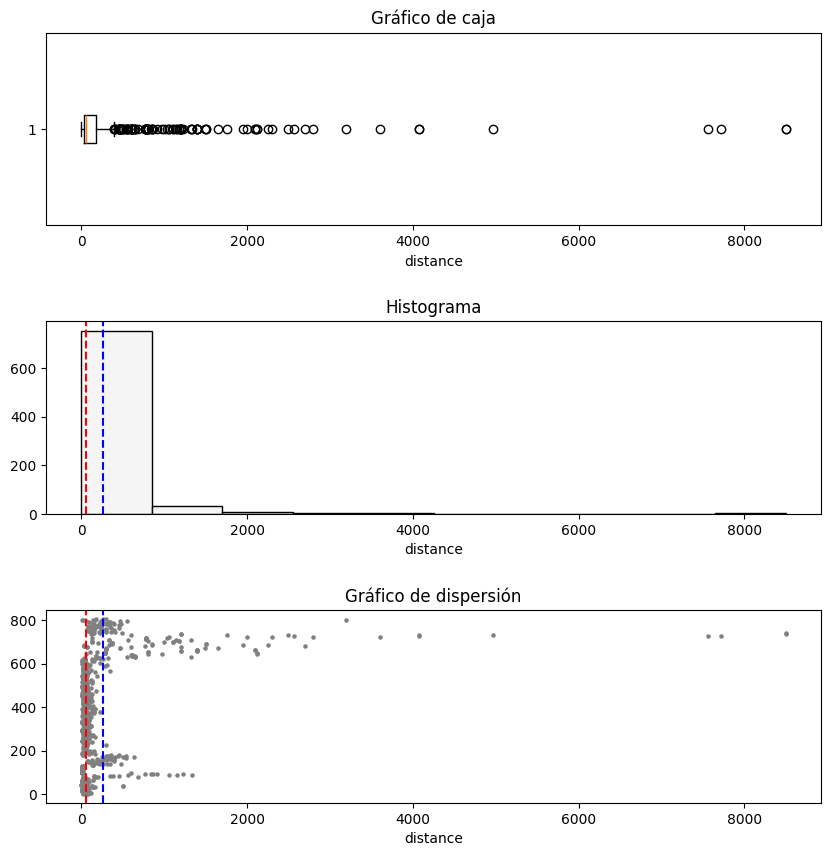

In [ ]:
fig, ax = plt.subplots(3, figsize = (10, 10), gridspec_kw = {'hspace': 0.5})
x_label = column_td
media = mtc[0]
mediana = mtc[1]

ax[0].boxplot(df_proyect_copy[x_label], vert = False)
ax[0].set_title('Gráfico de caja')
ax[0].set_xlabel(x_label)

ax[1].hist(df_proyect_copy[x_label], edgecolor = 'black', color = 'whitesmoke')
ax[1].axvline(x = mediana, linestyle = '--', color = 'red')
ax[1].axvline(x = media, linestyle = '--', color = 'blue')
ax[1].set_title('Histograma')
ax[1].set_xlabel(x_label)

x = range(len(df_proyect_copy[x_label]))
y = df_proyect_copy[x_label]

ax[2].scatter(y, x, s = 5, color = 'gray')
ax[2].axvline(x = mediana, linestyle = '--', color = 'red')
ax[2].axvline(x = media, linestyle = '--', color = 'blue')
ax[2].set_title('Gráfico de dispersión')
ax[2].set_xlabel(x_label)

plt.show()

##year

Año de descubrimiento

In [ ]:
column_td='year' #reutilizamos los bloques de código solo cambiamos de columna aquí

df_proyect_copy=df_proyect.dropna(subset=[column_td])

mtc = mtc_year = [round(df_proyect_copy[column_td].mean(), 2),
                      round(df_proyect_copy[column_td].median(), 2),
                      round(df_proyect_copy[column_td].mode().iloc[0], 2)] #reutilizamos los bloques de código solo cambiamos de columna aquí

std = std_year = np.std(df_proyect_copy[column_td]) #reutilizamos los bloques de código solo cambiamos de columna aquí

percentil = percentil_year = np.percentile(df_proyect_copy[column_td], [25, 50, 75]) #reutilizamos los bloques de código solo cambiamos de columna aquí

q_1 = round(percentil[0], 2)
q_3 = round(percentil[2], 2)
iqr = q_3 - q_1

print(f'Las MTC son: media {mtc[0]}, mediana {mtc[1]} y moda {mtc[2]}')
print(f'Las medidas de dispersión son: desviación estándar {std} y cuartiles {percentil}')

Las MTC son: media 2009.07, mediana 2010.0 y moda 2011
Las medidas de dispersión son: desviación estándar 3.9706472790001652 y cuartiles [2007. 2010. 2012.]


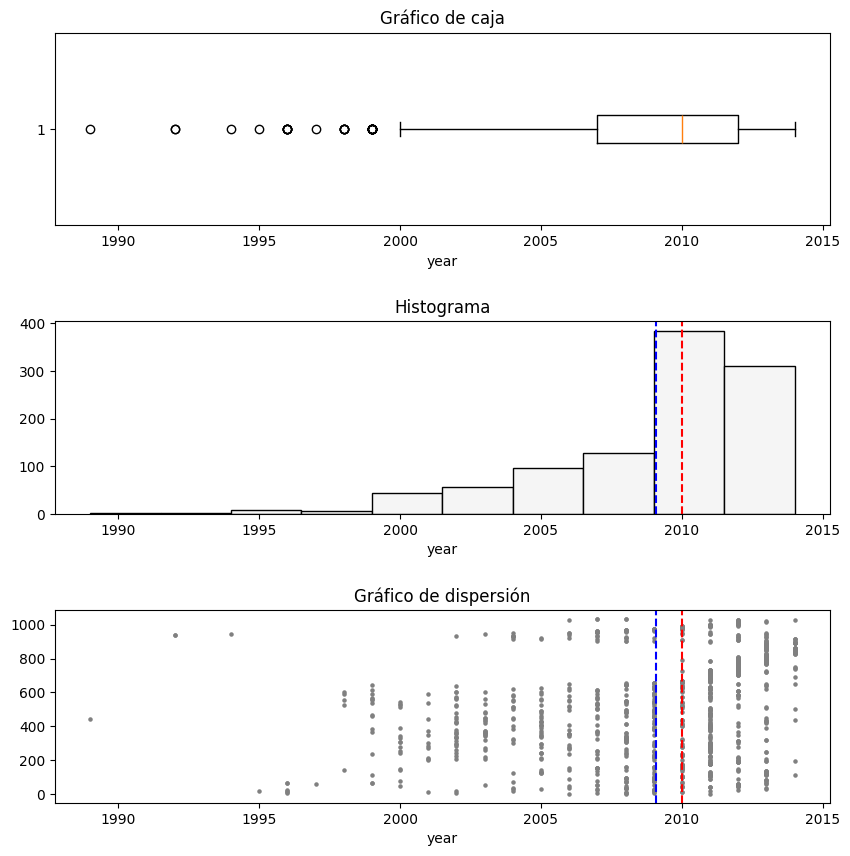

In [ ]:
fig, ax = plt.subplots(3, figsize = (10, 10), gridspec_kw = {'hspace': 0.5})
x_label = column_td
media = mtc[0]
mediana = mtc[1]

ax[0].boxplot(df_proyect_copy[x_label], vert = False)
ax[0].set_title('Gráfico de caja')
ax[0].set_xlabel(x_label)

ax[1].hist(df_proyect_copy[x_label], edgecolor = 'black', color = 'whitesmoke')
ax[1].axvline(x = mediana, linestyle = '--', color = 'red')
ax[1].axvline(x = media, linestyle = '--', color = 'blue')
ax[1].set_title('Histograma')
ax[1].set_xlabel(x_label)

x = range(len(df_proyect_copy[x_label]))
y = df_proyect_copy[x_label]

ax[2].scatter(y, x, s = 5, color = 'gray')
ax[2].axvline(x = mediana, linestyle = '--', color = 'red')
ax[2].axvline(x = media, linestyle = '--', color = 'blue')
ax[2].set_title('Gráfico de dispersión')
ax[2].set_xlabel(x_label)

plt.show()

Podemos ver que, con excepción de la masa y el año, los datos tiene varianzas bastante grandes. Esto es de esperarse, a estas escalas los números pueden variar bastante.

#Mapa de calor

In [ ]:
columnas = ['number',	'orbital_period',	'mass',	'distance',	'year']
corr = df_proyect[columnas].corr()
long_col = len(columnas)

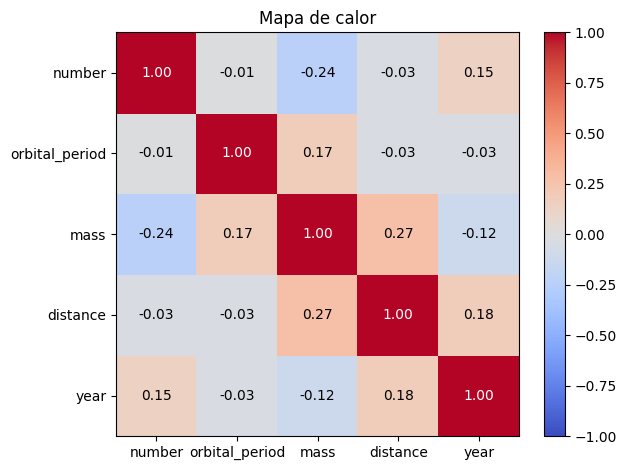

In [ ]:
corr_inv = corr.iloc[::-1]
heatmap = plt.pcolor(corr_inv, cmap = 'coolwarm', vmin = -1, vmax = 1)

plt.title('Mapa de calor')
plt.xticks(np.arange(0.5, long_col, 1), columnas)
plt.yticks(np.arange(0.5, long_col, 1), columnas[::-1])

for i in range(len(columnas)):
    for j in range(len(columnas)):
        val = round(corr_inv.iloc[i, j], 2)
        plt.text(j + 0.5, i + 0.5, f"{val:.2f}",
                 ha = 'center', va = 'center',
                 color = 'white' if abs(val) > 0.6 else 'black')

plt.colorbar(heatmap)
plt.tight_layout()
plt.show()

No parece haber una correlación entre las columnas de datos, pero hay una relación en específico que me gustaría explorar, la relación entre la masa del planeta y su periodo orbital.

Para cuerpos pequeños como planetas, el periodo que tarda un cuerpo en completar una órbita se deriva de la tercera ley de Kepler y es:

$$
T=2\pi\sqrt{\frac{r^2}{GM}}
$$

Donde:

$T$ es el periodo orbital

$r$ es el radio promedio de la orbita

$G$ es la constante de gravitación universal

$M$ es la masa del cuerpo central

Es decir, la masa del planeta no está involucrada, se espera que no haya relación entre la masa del planeta y el periodo orbital.

In [ ]:
corr_0 = round(df_proyect['mass'].corr(df_proyect['orbital_period']), 2)
corr_1 = round(df_proyect['mass'].corr(df_proyect['distance']), 2)
corr_2 = round(df_proyect['number'].corr(df_proyect['mass']), 2)
corr_3 = round(df_proyect['year'].corr(df_proyect['distance']), 2)

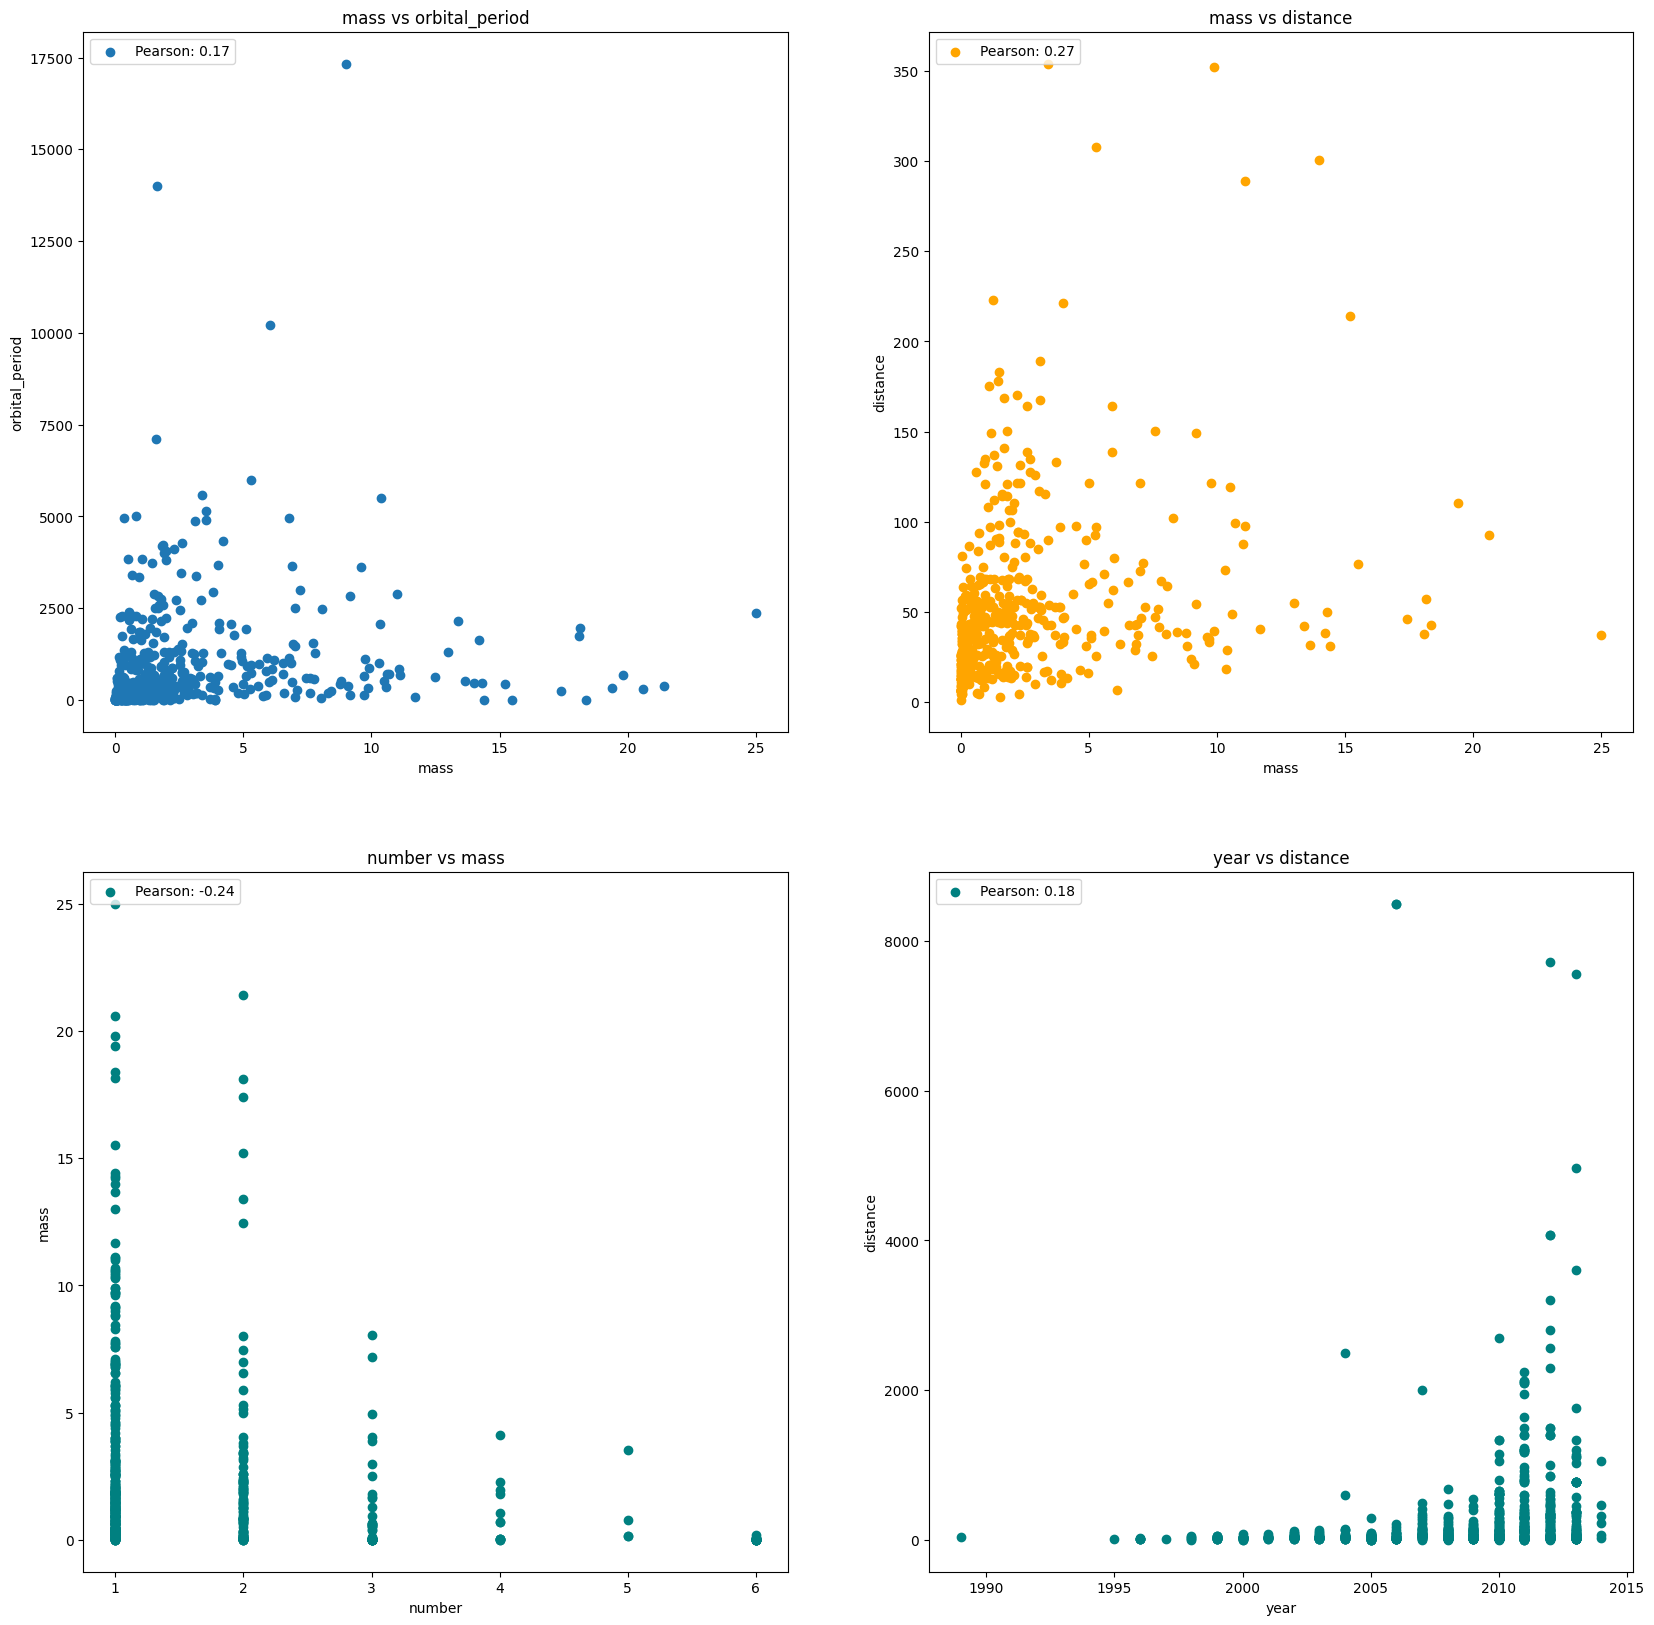

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(20, 20))

ax[0,0].scatter(data = df_proyect, x = 'mass', y = 'orbital_period', label = f'Pearson: {corr_0}')
ax[0,0].set_title('mass vs orbital_period')
ax[0,0].set_xlabel('mass')
ax[0,0].set_ylabel('orbital_period')
ax[0,0].legend(loc = 'upper left')

ax[0,1].scatter(data = df_proyect, x = 'mass', y = 'distance', color = 'Orange', label = f'Pearson: {corr_1}')
ax[0,1].set_title('mass vs distance')
ax[0,1].set_xlabel('mass')
ax[0,1].set_ylabel('distance')
ax[0,1].legend(loc = 'upper left')

ax[1,0].scatter(data = df_proyect, x = 'number', y = 'mass', color = 'teal', label = f'Pearson: {corr_2}')
ax[1,0].set_title('number vs mass')
ax[1,0].set_xlabel('number')
ax[1,0].set_ylabel('mass')
ax[1,0].legend(loc = 'upper left')

ax[1,1].scatter(data = df_proyect, x = 'year', y = 'distance', color = 'teal', label = f'Pearson: {corr_3}')
ax[1,1].set_title('year vs distance')
ax[1,1].set_xlabel('year')
ax[1,1].set_ylabel('distance')
ax[1,1].legend(loc = 'upper left')

Los gráficos, además de mostrar la poca correlación entre las columnas, nos presentan una relación que no parece reflejarse en este tipo de análisis. En el cuarto gráfico, se aprecia que a medida que pasa el tiempo se decubren planetas más y más alejados de nosotros. Podría ser por mejoras en la tecnología, mejoras en los métodos que usan los astronomos o puede que sea que tenemos muy pocos datos para realmente apreciar algo así.

#Prueba de Hipótesis

<Axes: xlabel='method'>

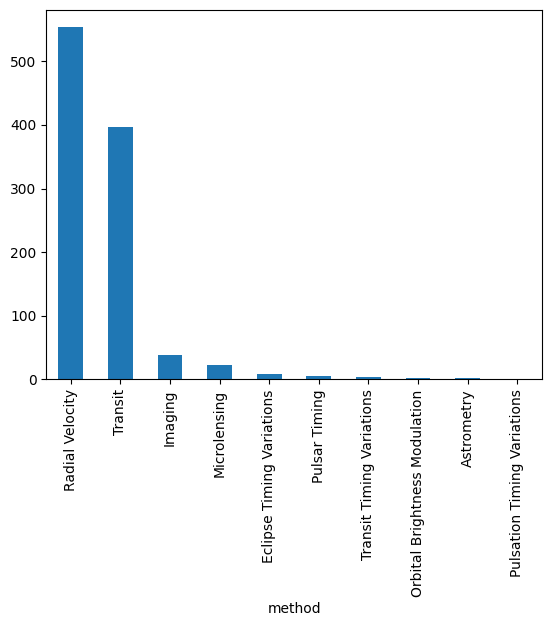

In [ ]:
df_proyect['method'].value_counts().plot(kind='bar')

Para la prueba de hipótesis, podemos ver que solo hay dos métodos que tienen suficientes datos como para compararlos entre ellos y hacer un buen análisis, tomando en cuenta la cantidad de datos del dataset.

In [ ]:
# Separación de grupos
df_proyect_copy = df_proyect.dropna(subset=['distance'])
d_radial_velocity = df_proyect_copy[df_proyect_copy['method'] == 'Radial Velocity']['distance']
d_transit = df_proyect_copy[df_proyect_copy['method'] == 'Transit']['distance']

In [ ]:
# Aplicar Prueba T de Student

t_stat, p_value = stats.ttest_ind(d_radial_velocity, d_transit)

print(f"Estadístico T: {t_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

Estadístico T: -13.7692
P-Value: 0.0000


In [ ]:
# Interpretación automática
if p_value < 0.01:
    print("\nConclusión: Rechazamos la Hipótesis Nula.")
    print("Existe una diferencia muy significativa entre las distancias de ambos grupos.")
elif p_value >= 0.01 and p_value < 0.05:
    print("\nConclusión: Rechazamos la Hipótesis Nula.")
    print("Existe una diferencia altamente significativa entre las distancias de ambos grupos.")
elif p_value >= 0.05 and p_value < 0.10:
    print("\nConclusión: Rechazamos la Hipótesis Nula.")
    print("Existe una diferencia moderadamente significativa entre las distancias de ambos grupos.")
else:
    print("\nConclusión: No podemos rechazar la Hipótesis Nula.")
    print("No hay evidencia suficiente para decir que las distancias son diferentes.")


Conclusión: Rechazamos la Hipótesis Nula.
Existe una diferencia muy significativa entre las distancias de ambos grupos.


<Axes: ylabel='Frequency'>

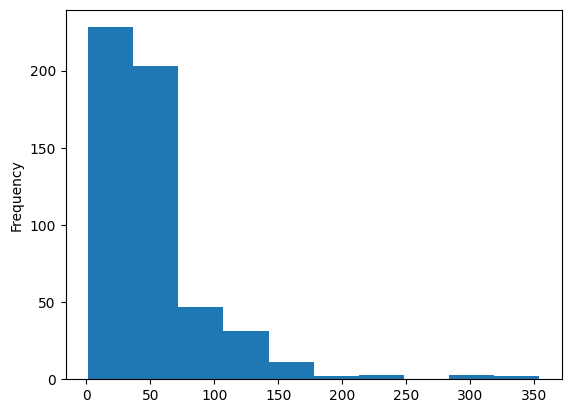

In [ ]:
df_proyect_copy[df_proyect_copy['method'] == 'Radial Velocity']['distance'].plot.hist(column='distance')

<Axes: ylabel='Frequency'>

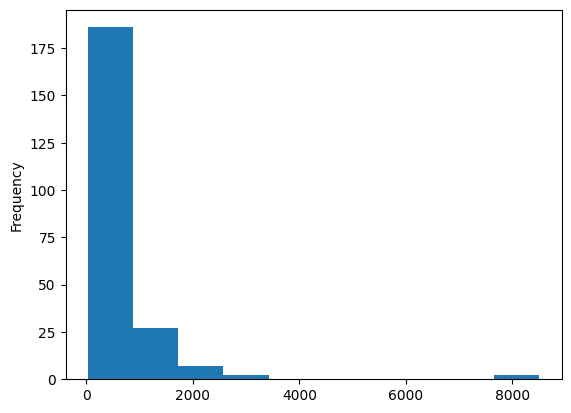

In [ ]:
df_proyect_copy[df_proyect_copy['method'] == 'Transit']['distance'].plot.hist(column='distance')

Después de rechazar la hipótesis nula y graficar los hisotgramas de las distancias de los métodos, nos damos cuenta que el método transit tiene buenos resultados al encontrar planetas a distancias más grandes.

#Regresión lineal

In [ ]:
# Definir regresión lineal
df_proyect_copy = df_proyect.dropna(subset= ['mass','orbital_period'])

x=df_proyect_copy['mass']
y=df_proyect_copy['orbital_period']
linear_regression = np.polyfit(x, y, 1)
beta, alpha = linear_regression

print(f'y = {beta} x + {alpha}')

y = 68.95378555558584 x + 668.2737023623487


In [ ]:
y_pred = np.poly1d(linear_regression)(x)
r = np.corrcoef(y, y_pred)[0, 1]
r**2 #coeficiente de correlación

np.float64(0.03018053913016254)

#Descenso de gradiente

In [ ]:
tamaño_paso = 0.01
theta_0 = 0
theta_1 = 0

perdida = []

n=len(df_proyect_copy['mass'])

num_iteraciones = 100

for i in range(num_iteraciones):
    y_pred = theta_1 * x + theta_0
    error = ((y_pred - y) ** 2).mean()
    perdida.append(error)

    d_theta_0 = (2 / n) * np.sum(y_pred - y)
    d_theta_1 = (2 / n) * np.sum((y_pred - y) * x)

    theta_0 = theta_0 - tamaño_paso * d_theta_0
    theta_1 = theta_1 - tamaño_paso * d_theta_1

print(f'y = {theta_1} x + {theta_0}')

y = 90.43724774563525 x + 498.5080604199109


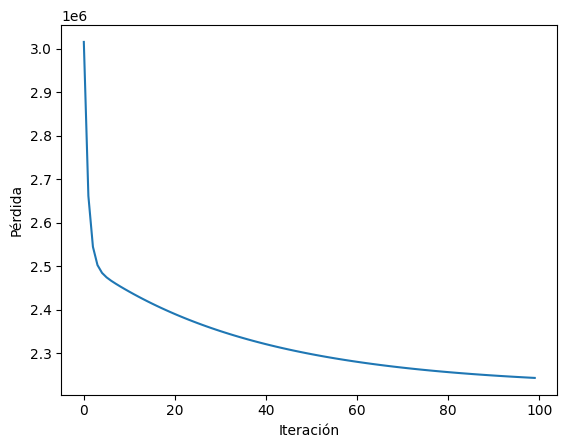

In [ ]:
plt.plot(perdida)
plt.xlabel('Iteración')
plt.ylabel('Pérdida')
plt.show()

In [ ]:
perdida[-1]

np.float64(2243575.8777988083)

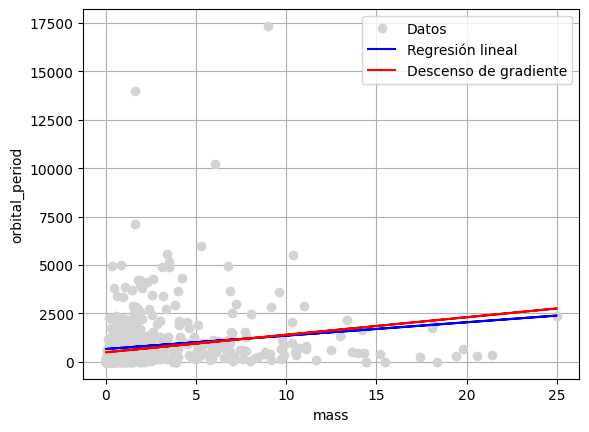

In [ ]:
plt.plot(x, y, 'o', color = 'lightgray', label = 'Datos')
plt.plot(x, beta*x + alpha, color = 'blue', label = 'Regresión lineal')
plt.plot(x, theta_1 * x + theta_0, color = 'red', label = 'Descenso de gradiente')
plt.xlabel('mass')
plt.ylabel('orbital_period')
plt.legend()
plt.grid()
plt.show()

Del coeficiente de correlación y la pérdida del descenso de gradiente, podemos concluir que la relación entre la masa y el periodo orbital es casi inexistente. Esto es lo que esperamos de la tercera ley de Kepler.